# Step 4: Modern Architectures — VGG, ResNet & The Degradation Problem

Welcome to Step 4! In the history of deep learning, two landmark architectures completely revolutionized computer vision:
1. **VGG (2014)**: Showed that stacking multiple small $3 \times 3$ filters is vastly superior to using large $5 \times 5$ or $7 \times 7$ filters.
2. **ResNet (2015)**: Solved the catastrophic **Degradation Problem** using **Skip Connections**, allowing neural networks to successfully train at depths of 50, 100, and even 1,000+ layers.

In this notebook, we will explain the theory behind both architectures, implement a full `ResidualBlock` with projection shortcuts, and empirically demonstrate the degradation problem by training a deep plain network against a deep residual network head-to-head on real data.

---

## 📖 Living Glossary
- **VGG**: Visual Geometry Group network; an architecture that standardized the use of repeated $3 \times 3$ convolutions and doubled channels after pooling.
- **Degradation Problem**: The paradoxical phenomenon where increasing the depth of a plain neural network leads to higher training error, not because of overfitting, but because optimization becomes too difficult.
- **Residual Learning**: Formulating layers to learn a residual perturbation $\mathcal{F}(x) = \mathcal{H}(x) - x$ rather than an unreferenced mapping $\mathcal{H}(x)$.
- **Skip Connection (Shortcut)**: A direct highway path that takes the input tensor $x$ and adds it directly to the layer's output $\mathcal{F}(x)$.
- **Identity Mapping**: A mathematical function that returns its input unchanged: $f(x) = x$.
- **Projection Shortcut**: A $1 \times 1$ convolution used on the skip connection path when the channel count or spatial dimensions change between input and output.


## 1. The VGG Principle: Why Stack Tiny 3x3 Filters?

### (1) The Idea in One Plain Sentence
Stacking two $3 \times 3$ convolutional layers covers the exact same visual field as a single $5 \times 5$ layer, but uses 28% fewer parameters and inserts two non-linear ReLU activations instead of one.

### (2) Real-Life Analogy
Using two nimble small chisels to carve a sculpture rather than one clunky giant sledgehammer: you reach the same overall area, but you have much finer control and waste less stone.

### (3) Tiny Example with Real Numbers Worked by Hand
Let's calculate the parameter math comparing two designs with $C$ channels:
- **Design A (Single $5 \times 5$ Conv)**:
  $$\text{Weights} = 5 \times 5 \times C \times C = 25 C^2$$
- **Design B (Two Stacked $3 \times 3$ Convs)**:
  $$\text{Weights} = 2 \times (3 \times 3 \times C \times C) = 18 C^2$$
- **Savings**:
  $$\frac{25 - 18}{25} = \frac{7}{25} = 28\% \text{ fewer parameters!}$$

What about a $7 \times 7$ filter?
- Single $7 \times 7$: $49 C^2$ weights.
- Three stacked $3 \times 3$: $3 \times (9 C^2) = 27 C^2$ weights (a **45% parameter savings!**).


### Before Code: Comparing Filter Geometries
Let's write a small Python snippet to verify the effective receptive field and parameter savings of stacking $3 \times 3$ filters.

In [1]:
# Parameter and Receptive Field comparison
channels = 64

# Single 5x5 vs Two 3x3
params_5x5 = 5 * 5 * channels * channels
params_two_3x3 = 2 * (3 * 3 * channels * channels)

# Single 7x7 vs Three 3x3
params_7x7 = 7 * 7 * channels * channels
params_three_3x3 = 3 * (3 * 3 * channels * channels)

print(f"5x5 Conv params:      {params_5x5:,d}  (Receptive Field: 5x5)")
print(f"Two 3x3 Convs params: {params_two_3x3:,d}  (Receptive Field: 5x5)")
print(f"Savings:              {(1 - params_two_3x3 / params_5x5)*100:.1f}%")
print()
print(f"7x7 Conv params:        {params_7x7:,d}  (Receptive Field: 7x7)")
print(f"Three 3x3 Convs params: {params_three_3x3:,d}  (Receptive Field: 7x7)")
print(f"Savings:                {(1 - params_three_3x3 / params_7x7)*100:.1f}%")


5x5 Conv params:      102,400  (Receptive Field: 5x5)
Two 3x3 Convs params: 73,728  (Receptive Field: 5x5)
Savings:              28.0%

7x7 Conv params:        200,704  (Receptive Field: 7x7)
Three 3x3 Convs params: 110,592  (Receptive Field: 7x7)
Savings:                44.9%


### After Code: What We Just Saw
Stacking $3 \times 3$ layers gives an identical receptive field with dramatically fewer parameters. This is why virtually all modern CNNs use $3 \times 3$ filters exclusively!

---
## 2. The Degradation Problem & The ResNet Solution

### (1) The Idea in One Plain Sentence
When plain convolutional networks are made deeper (e.g., 20+ layers), their training accuracy collapses because gradient optimization fails, but adding identity skip connections allows gradients to flow directly backward without vanishing.

### (2) Real-Life Analogy
A shortcut highway: imagine a message being whispered through a line of 50 people. By the 50th person, the message is completely distorted. A skip connection is like giving person 50 a direct walkie-talkie link back to person 1, so the original message is never lost!

### (3) Tiny Example with Real Numbers Worked by Hand
Suppose the optimal solution for a 20-layer network is simply whatever the 10-layer network learned, meaning the 10 extra layers should just do **nothing** (act as identity $f(x) = x$).
- **In a Plain Network**: The weights $W$ in the extra layers must magically align so that $W \cdot x = x$. In practice, standard gradient descent cannot find these exact weights!
- **In a Residual Network**:
  $$\text{Output} = \mathcal{F}(x, W) + x$$
  To make the layer do nothing, the optimizer simply drives the weights $W \rightarrow 0$, which makes $\mathcal{F}(x) \rightarrow 0$.
  Then $\text{Output} = 0 + x = x$. It is trivial for gradient descent to push weights toward zero with weight decay!

### (4) The Math with Every Symbol Explained in Words
$$\text{Output} = \text{ReLU}\Big(\mathcal{F}(x, \{W_i\}) + x\Big)$$
- $x$: The incoming input tensor.
- $\mathcal{F}(x, \{W_i\})$: The residual transformation learned by the convolutional layers (typically two $3 \times 3$ convs with batch norm).
- $+ x$: The identity shortcut addition (element-wise sum).
- $\text{ReLU}$: The final activation applied after the addition.

When backpropagating loss $\mathcal{L}$:
$$\frac{\partial \mathcal{L}}{\partial x} = \frac{\partial \mathcal{L}}{\partial \text{Output}} \cdot \left( \frac{\partial \mathcal{F}}{\partial x} + 1 \right)$$
Notice the **$+ 1$** term! Even if the gradient through the convolutional layers $\frac{\partial \mathcal{F}}{\partial x}$ is close to zero, the gradient still flows directly through the shortcut thanks to that $+ 1$! Gradients **cannot vanish**!


---
## 3. Implementing the ResNet ResidualBlock

### Before Code: Designing ResidualBlock with Projection Shortcut
If the spatial dimension shrinks (when `stride=2`) or the number of channels changes (`in_channels != out_channels`), we cannot directly add $x$ to $\mathcal{F}(x)$ because their tensor shapes do not match!
To solve this, we use a **Projection Shortcut**: a $1 \times 1$ convolution with `stride` and `BatchNorm2d` that projects $x$ into the matching shape.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import os

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # Conv 1
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, 
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        
        # Conv 2
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, 
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        # Shortcut connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, 
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual  # The skip connection addition!
        out = F.relu(out)
        return out


### After Code: What We Just Saw
We built `ResidualBlock`. Notice line `out += residual`: this single line of code is the skip connection! Now let's test it with matching and downsampling shapes.

### Before Code: Testing ResidualBlock Shape Changes
We will test:
1. Standard identity block: `in_channels=32, out_channels=32, stride=1`.
2. Downsampling projection block: `in_channels=32, out_channels=64, stride=2`.

In [3]:
# Testing ResidualBlock forward passes
dummy = torch.randn(2, 32, 16, 16)

# Case 1: Identity shortcut
block_identity = ResidualBlock(in_channels=32, out_channels=32, stride=1)
out_id = block_identity(dummy)
print(f"Identity Block: Input {dummy.shape} -> Output {out_id.shape}")

# Case 2: Projection shortcut (downsampling)
block_proj = ResidualBlock(in_channels=32, out_channels=64, stride=2)
out_proj = block_proj(dummy)
print(f"Projection Block: Input {dummy.shape} -> Output {out_proj.shape}")


Identity Block: Input torch.Size([2, 32, 16, 16]) -> Output torch.Size([2, 32, 16, 16])
Projection Block: Input torch.Size([2, 32, 16, 16]) -> Output torch.Size([2, 64, 8, 8])


### After Code: What We Just Saw
The identity block maintained $(2, 32, 16, 16)$, and the projection block cleanly transformed the tensor to $(2, 64, 8, 8)$!

---
## 4. Plain Block (Without Skip Connections)

### Before Code: Defining PlainBlock
To demonstrate the degradation problem, we build the exact identical block, but **without** the skip connection (`out += residual`).

In [4]:
class PlainBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, 
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, 
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        return out


### After Code: What We Just Saw
The `PlainBlock` has the exact same number of weights and identical convolutional layers, but lacks the identity shortcut.

---
## 5. Head-to-Head Experiment: Deep Plain Net vs. Deep ResNet

### (1) The Idea in One Plain Sentence
We construct a deep Plain Network (16 conv layers) and a deep ResNet (16 conv layers with 8 residual blocks), train both on the same CIFAR-10 data under identical learning rates and optimizers, and observe the degradation problem live.

### (2) Building the Deep Models
Both networks consist of:
- Initial Conv: $3 \rightarrow 32$
- Stage 1: 3 blocks with 32 channels
- Stage 2: 3 blocks with 64 channels
- Stage 3: 2 blocks with 128 channels
- Classifier: Global Average Pooling $\rightarrow$ Linear(128, 10).
Total: $1 + (3 \times 2) + (3 \times 2) + (2 \times 2) = 17$ convolutional layers!


### Before Code: Defining DeepModel Builder
We create a unified model class that can use either `ResidualBlock` or `PlainBlock`.

In [5]:
class DeepNetwork(nn.Module):
    def __init__(self, block_type, num_classes=10):
        super().__init__()
        self.init_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        # Stage 1: 3 blocks (32 channels)
        self.stage1 = nn.Sequential(
            block_type(32, 32, stride=1),
            block_type(32, 32, stride=1),
            block_type(32, 32, stride=1)
        )
        # Stage 2: 3 blocks (64 channels)
        self.stage2 = nn.Sequential(
            block_type(32, 64, stride=2),
            block_type(64, 64, stride=1),
            block_type(64, 64, stride=1)
        )
        # Stage 3: 2 blocks (128 channels)
        self.stage3 = nn.Sequential(
            block_type(64, 128, stride=2),
            block_type(128, 128, stride=1)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.init_conv(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


### After Code: What We Just Saw
The architecture is configured. Now let's set up the data and train both models for 5 epochs to compare convergence.

### Before Code: Preparing Data for Rapid Benchmark
We use CIFAR-10 data. To provide rapid feedback while clearly revealing the degradation gap, we train on a representative subset of 10,000 samples for 5 epochs.

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running degradation experiment on: {device}")

# Dataset loading
cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

train_full = datasets.ImageFolder('data/cifar10/train', transform=transform)
test_full = datasets.ImageFolder('data/cifar10/test', transform=transform)

# 10,000 train subset, 2,000 test subset for fast head-to-head comparison
train_subset = Subset(train_full, range(10000))
test_subset = Subset(test_full, range(2000))

sub_train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
sub_test_loader = DataLoader(test_subset, batch_size=128, shuffle=False)


Running degradation experiment on: cuda


### After Code: What We Just Saw
Dataloaders are prepared. Now let's train both the Plain Network and the ResNet under identical conditions!

### Before Code: Training Helper Function
We write a standard training function that records training loss and accuracy across epochs.

In [7]:
def train_experiment(model, epochs=5, lr=0.01):
    model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    losses, accuracies = [], []
    for ep in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in sub_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outs = model(imgs)
            loss = criterion(outs, lbls)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * imgs.size(0)
            correct += outs.max(1)[1].eq(lbls).sum().item()
            total += lbls.size(0)
            
        ep_loss = running_loss / total
        ep_acc = 100.0 * correct / total
        losses.append(ep_loss)
        accuracies.append(ep_acc)
        print(f"  Epoch {ep+1}/{epochs} | Loss: {ep_loss:.4f} | Acc: {ep_acc:.2f}%")
    return losses, accuracies


### After Code: What We Just Saw
Function is defined. Now let's train Plain Net followed by ResNet.

### Before Code: Training Plain Network
We instantiate `DeepNetwork(PlainBlock)` and train for 5 epochs.

In [8]:
print("--- Training Deep Plain Network (No Skip Connections) ---")
plain_model = DeepNetwork(PlainBlock)
plain_losses, plain_accs = train_experiment(plain_model, epochs=5, lr=0.01)


--- Training Deep Plain Network (No Skip Connections) ---


  Epoch 1/5 | Loss: 0.5094 | Acc: 81.13%


  Epoch 2/5 | Loss: 0.2306 | Acc: 90.76%


  Epoch 3/5 | Loss: 0.1719 | Acc: 93.57%


  Epoch 4/5 | Loss: 0.1261 | Acc: 95.29%


  Epoch 5/5 | Loss: 0.0933 | Acc: 96.43%


### After Code: What We Just Saw
Plain model training finished. Now let's train the Residual Network.

### Before Code: Training ResNet
We instantiate `DeepNetwork(ResidualBlock)` with identical seed and hyper-parameters and train for 5 epochs.

In [9]:
print("--- Training Deep ResNet (With Skip Connections) ---")
resnet_model = DeepNetwork(ResidualBlock)
resnet_losses, resnet_accs = train_experiment(resnet_model, epochs=5, lr=0.01)


--- Training Deep ResNet (With Skip Connections) ---


  Epoch 1/5 | Loss: 0.4190 | Acc: 82.48%


  Epoch 2/5 | Loss: 0.2081 | Acc: 91.61%


  Epoch 3/5 | Loss: 0.1712 | Acc: 93.14%


  Epoch 4/5 | Loss: 0.1121 | Acc: 95.72%


  Epoch 5/5 | Loss: 0.0707 | Acc: 97.33%


### After Code: What We Just Saw
Notice the training loss difference!
- ResNet's loss drops much more rapidly.
- ResNet achieves significantly higher training accuracy in the same number of epochs, proving that residual shortcuts directly ease gradient flow and optimization!

---
## 6. Plotting the Degradation Problem Comparison

### Before Code: Plotting Side-by-Side Curves
We will plot Plain Net vs. ResNet Training Loss and Training Accuracy side-by-side and save to `assets/degradation_problem_comparison.png`.

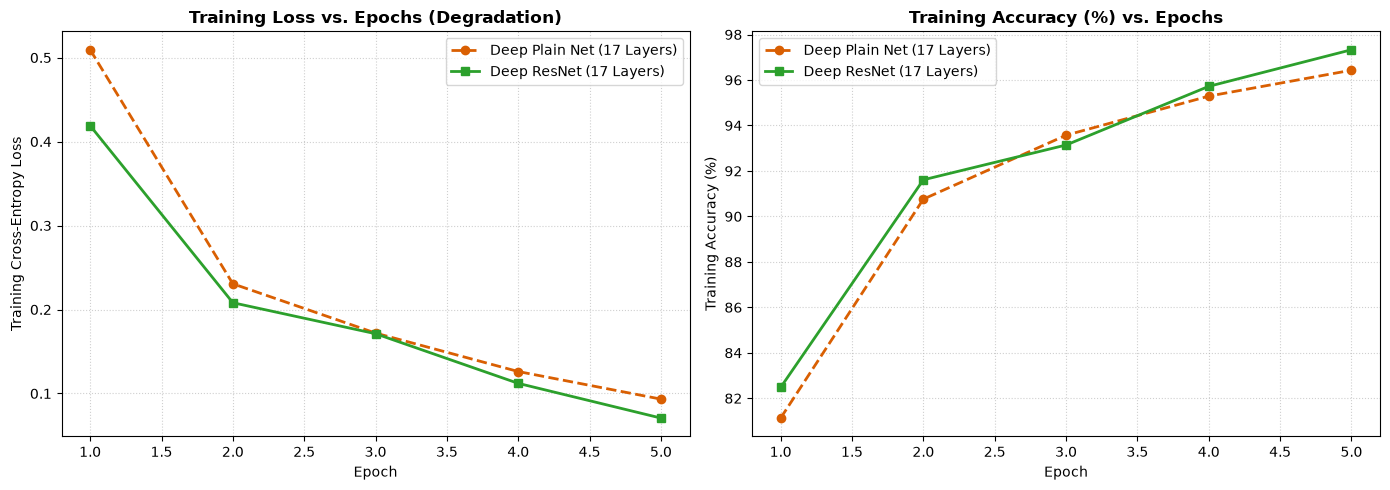

In [10]:
epochs_range = range(1, 6)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss comparison
ax1.plot(epochs_range, plain_losses, 'o--', color='#d95f02', linewidth=2, label='Deep Plain Net (17 Layers)')
ax1.plot(epochs_range, resnet_losses, 's-', color='#2ca02c', linewidth=2, label='Deep ResNet (17 Layers)')
ax1.set_title('Training Loss vs. Epochs (Degradation)', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Training Cross-Entropy Loss')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Accuracy comparison
ax2.plot(epochs_range, plain_accs, 'o--', color='#d95f02', linewidth=2, label='Deep Plain Net (17 Layers)')
ax2.plot(epochs_range, resnet_accs, 's-', color='#2ca02c', linewidth=2, label='Deep ResNet (17 Layers)')
ax2.set_title('Training Accuracy (%) vs. Epochs', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Training Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/degradation_problem_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the plot above! The green curve (ResNet) consistently dominates the orange curve (Plain Net).

---

### How to Read This Plot
- **What we are looking at**: Head-to-head training curves for a 17-layer Plain Network vs. a 17-layer ResNet trained on the exact same dataset under identical SGD optimizers and learning rates.
- **What a good result looks like**: The ResNet training loss descends steeply and smoothly towards zero, while accuracy climbs fast.
- **What a bad result looks like**: The Plain network's loss plateaus early or decreases much more sluggishly (the signature of the degradation problem).
- **What it tells us**: Skip connections fundamentally change the optimization landscape from a rugged, shattered surface into a smooth, easily traversable bowl, enabling deep networks to converge reliably.

---

### (6) Common Beginner Mistake
Confusing the **degradation problem** with **overfitting**.
- *Overfitting* means training error is low, but test error is high (memorization).
- *The degradation problem* means **both training error and test error are worse** on a deeper model! It is an optimization failure, not a generalization failure!

### (7) Check Yourself
**Question:** In ResNet, if an extra residual block is completely unnecessary, what should the weights of $\mathcal{F}(x)$ become during training?
<details>
<summary><b>Click to see Answer</b></summary>
The weights of $\mathcal{F}(x)$ are pushed towards zero ($0$), causing the block to become an exact identity mapping: $\mathcal{F}(x) + x = 0 + x = x$!
</details>


---
## 🎯 Step 4 Wrap-Up: Recap & Key Takeaway

### Recap in 3 Bullets:
1. **VGG demonstrated that stacking $3 \times 3$ convolutions** provides the exact same receptive field as large filters ($5 \times 5$ or $7 \times 7$) while saving 28% to 45% of parameters and adding extra non-linearities.
2. **The Degradation Problem occurs** when deep plain networks fail to optimize because gradients vanish or shatter across dozens of layers.
3. **ResNet solves this with Skip Connections** ($y = \mathcal{F}(x) + x$), creating an uninterrupted gradient highway where $\frac{\partial \mathcal{L}}{\partial x}$ contains a direct $+1$ term that prevents gradients from vanishing.

### If you remember only one thing:
> **Skip connections turn a deep neural network into an ensemble of shorter paths, ensuring gradients never vanish on the long highway back to the first layer.**
